# MicroDuck 跨缝跳跃：起跳、落地与 PPO 续训

让小鸭子从高平台跃过 30 cm 间隙，落到低 25 cm 的平台上。
先加载社区训练模型，运行完整仿真；再续训 10 轮、导出 ONNX，并在同一场景比较结果。
PyTorch 策略在 GPU 上推理，MuJoCo/Warp 计算接触与运动，Notebook 直接播放本次生成的视频。

这是现有 8 本教程之外的拓展实验，原有短期和月度学习安排保持不变。
本实验使用专门的跨平台任务，当前只验证仿真，不连接开发板或真实机器人。

## 1. 默认参数与输出位置

推荐在 Ubuntu 的 Jupyter 中运行。单元格会准备独立的任务环境，不修改其它教程的依赖。
模型和上游代码下载到共享资料目录；重复运行覆盖本实验的最新视频和续训模型。
原始模型保持不变，可随时重新比较。

In [1]:
import os
import json
from pathlib import Path
import sys
import shlex
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Video, Image, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

def locate_topic():
    if os.getenv("MICRODUCK_TOPIC_ROOT"):
        return Path(os.environ["MICRODUCK_TOPIC_ROOT"]).expanduser().resolve()
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "02-可运行代码/long-jump-learning").is_dir():
            return base
    raise FileNotFoundError("请从本专题启动 Jupyter，或设置 MICRODUCK_TOPIC_ROOT。")

TOPIC = locate_topic()
CODE = TOPIC / "02-可运行代码/long-jump-learning"
HOME = Path(os.getenv("MICRODUCK_JUMP_HOME", str(Path.home() / "projects/robotics_shared/downloads/microduck-long-jump")))
OUTPUT = TOPIC / "03-Notebook/outputs/long_jump"
OUTPUT.mkdir(parents=True, exist_ok=True)
PROXY = os.getenv("MICRODUCK_DOWNLOAD_PROXY") or None
sys.path.insert(0, str(CODE))
import jump_lesson as lesson
SEED, TRAIN_ENVS, TRAIN_ITERATIONS = 28, 64, 10
print({"task": lesson.TASK, "seed": SEED, "gap_m": 0.30, "drop_m": 0.25})
print("续训设置：64 个环境，10 个 PPO 更新轮次；原始模型保留。")

{'task': 'Mjlab-PlatformJump-MicroDuck', 'seed': 28, 'gap_m': 0.3, 'drop_m': 0.25}
续训设置：64 个环境，10 个 PPO 更新轮次；原始模型保留。


## 2. 获取上游代码与模型

[社区任务源码](https://github.com/Vottivott/microduck-playground/tree/b6aed572587b52e41a452a9b2be517c95d2b3d96/experiments/parkour/long-jump)
与 [模型包](https://huggingface.co/HannesVonEssen/microduck-long-jump)分别固定版本。
下载后核验 SHA-256，避免把不同任务的模型或配置混用。
训练检查点使用 PyTorch 文件格式，只加载这里指定的可信来源。

In [2]:
SOURCE, MODEL = lesson.prepare_assets(HOME, proxy=PROXY)
print("源码版本：", lesson.SOURCE_REVISION)
print("模型版本：", lesson.MODEL_REVISION)
for name in ("checkpoint.pt", "policy.onnx"):
    print(name, "SHA-256:", lesson.sha256(MODEL / name))
print("模型、命令配置和源码版本检查通过。")

源码版本： b6aed572587b52e41a452a9b2be517c95d2b3d96
模型版本： fdcdc787e72b8784bb842159ee70607859cd17ed
checkpoint.pt SHA-256: 114ab38724b1bea789b0d3f12a1a18a5981b40572863117e212a2a0601f9ed4a
policy.onnx SHA-256: cbd366e4ec6b95dd989d795cb73e1cf28731f85114c60368542dc9605a46fe06
模型、命令配置和源码版本检查通过。


## 3. 准备独立环境

`uv sync --locked` 按上游锁文件安装依赖。需要 Python 3.12、CUDA 和 EGL；首次准备会下载依赖。
后续运行复用环境，不会重新训练或下载已核验的模型。

In [3]:
PYTHON, setup = lesson.prepare_environment(SOURCE, HOME, proxy=PROXY)
print({"environment_ready": PYTHON.is_file(), "setup_seconds": setup["seconds"]})
runtime = lesson.inspect_runtime(SOURCE, PYTHON, OUTPUT)
print({"cuda_available": runtime["cuda_available"], "versions": runtime["versions"],
       "control_dt_s": runtime["control_dt_s"]})

{'environment_ready': True, 'setup_seconds': 332.2}


{'cuda_available': True, 'versions': {'torch': '2.9.1+cu129', 'mjlab': '1.3.0', 'mujoco': '3.10.0', 'mujoco-warp': '3.8.1', 'onnx': '1.22.0', 'rsl-rl-lib': '5.0.1'}, 'control_dt_s': 0.02}


## 4. 策略、奖励与任务接口

Actor 根据观测输出 14 个关节动作；Critic 用于 PPO 训练。
本任务的 61 维观测包含机器人状态、上一时刻动作与命令。
六维身体命令中的前两项表示 `gap / 0.3`、`drop / 0.3`；模型本身不读取摄像头。
已导出的 ONNX 包含观测归一化与动作边界，不能再额外归一化一次。

In [4]:
contract = json.loads((MODEL / "config.json").read_text(encoding="utf-8"))
manifest = json.loads((MODEL / "manifest.json").read_text(encoding="utf-8"))
print("任务：", manifest["task"], "；原始训练轮次：", manifest["stored_iteration"])
print("命令示例：", [0.30 / 0.3, 0.25 / 0.3, 0, 0, 0, 0])
print("观测各段：", contract["observation_layout"])
print("网络配置：", json.dumps(runtime["network"], ensure_ascii=False, indent=2))
print("奖励项：", runtime["reward_names"])
print("终止项：", runtime["termination_names"])

任务： Mjlab-PlatformJump-MicroDuck ；原始训练轮次： 15250
命令示例： [1.0, 0.8333333333333334, 0, 0, 0, 0]
观测各段： {'base_ang_vel': [0, 3], 'projected_gravity': [3, 6], 'joint_pos_minus_offset': [6, 20], 'joint_vel': [20, 34], 'previous_bounded_action': [34, 48], 'twist_command': [48, 51], 'head_command': [51, 55], 'body_command': [55, 61]}
网络配置： {
  "actor": {
    "hidden_dims": [
      512,
      256,
      128
    ],
    "activation": "elu",
    "obs_normalization": true,
    "cnn_cfg": null,
    "distribution_cfg": {
      "class_name": "GaussianDistribution",
      "init_std": 0.8,
      "std_type": "scalar"
    },
    "rnn_type": null,
    "rnn_hidden_dim": 256,
    "rnn_num_layers": 1,
    "class_name": "MLPModel"
  },
  "critic": {
    "hidden_dims": [
      512,
      256,
      128
    ],
    "activation": "elu",
    "obs_normalization": true,
    "cnn_cfg": null,
    "distribution_cfg": null,
    "rnn_type": null,
    "rnn_hidden_dim": 256,
    "rnn_num_layers": 1,
    "class_name": "MLPMode

## 5. 看懂场景几何

起点平台顶面高 35 cm，目标平台高 10 cm。两平台之间的间隙为 30 cm。
下图是尺寸示意，真正的接触和跳跃由下一单元的物理仿真计算。

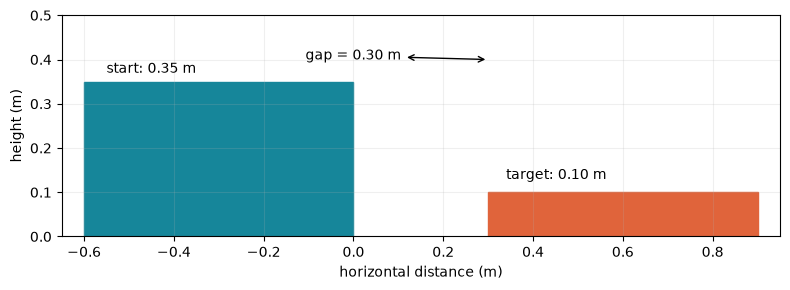

本次评测固定间隙与高差；续训使用上游课程范围。


In [5]:
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(8, 3))
ax.add_patch(Rectangle((-0.6, 0), 0.6, 0.35, color="#16869a"))
ax.add_patch(Rectangle((0.3, 0), 0.6, 0.10, color="#e0643b"))
ax.annotate("gap = 0.30 m", xy=(0.30, 0.40), xytext=(0, 0.40),
            arrowprops={"arrowstyle": "<->"}, ha="center")
ax.text(-0.55, 0.37, "start: 0.35 m")
ax.text(0.34, 0.13, "target: 0.10 m")
ax.set(xlim=(-0.65, 0.95), ylim=(0, 0.50), xlabel="horizontal distance (m)", ylabel="height (m)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("本次评测固定间隙与高差；续训使用上游课程范围。")

## 6. 先运行原始模型

从初始状态运行一个完整回合，最长 12 秒，保留起跳、落地和落地后的运动。
仿真一旦终止便结束录制，不把自动重置后的画面接到视频末尾。
固定随机种子，不从多次实验中挑选片段。

In [6]:
baseline = lesson.render_episode(SOURCE, PYTHON, MODEL / "checkpoint.pt",
                                 OUTPUT / "long_jump_pretrained_latest.mp4", seed=SEED)
print({key: baseline[key] for key in ("backend", "video_seconds", "termination", "landed_on_target", "final_target_support", "final_position_m")})
display(Video("outputs/long_jump/long_jump_pretrained_latest.mp4", embed=False, width=720,
              html_attributes='controls style="max-width:100%;height:auto;"'))

{'backend': 'PyTorch CUDA', 'video_seconds': 12.0, 'termination': ['time_out'], 'landed_on_target': True, 'final_target_support': True, 'final_position_m': [0.44053444266319275, 0.0065956865437328815, 0.2104416936635971]}


## 7. 观察实际轨迹

轨迹来自模拟器中的机器人状态。位置与身体竖直方向一起观察，可以区分跨缝、落地与跌倒。
完整视频和终止项需要一起看，达到时长并不能单独说明落点正确。

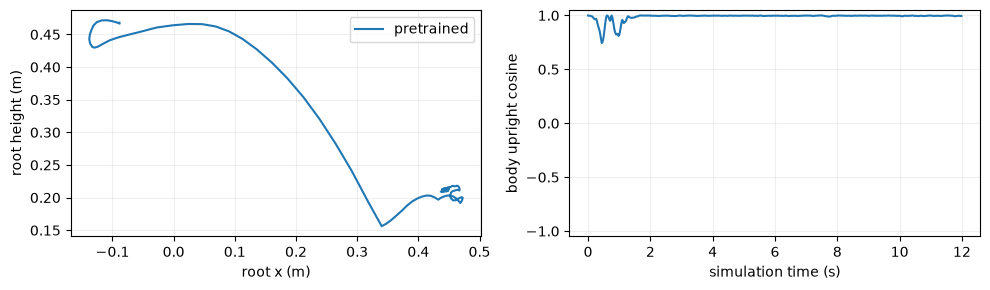

原始模型完整回合： 12.0 秒；终止项： ['time_out']


In [7]:
def plot_episode(report, axis, label):
    trace = report["trace"]
    axis.plot([r["x_m"] for r in trace], [r["z_m"] for r in trace], label=label)
    axis.set(xlabel="root x (m)", ylabel="root height (m)")
    axis.grid(alpha=0.2)
    axis.legend()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
plot_episode(baseline, axes[0], "pretrained")
axes[1].plot([r["time_s"] for r in baseline["trace"]],
             [r["upright_cos"] for r in baseline["trace"]])
axes[1].set(xlabel="simulation time (s)", ylabel="body upright cosine", ylim=(-1.05, 1.05))
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("原始模型完整回合：", baseline["video_seconds"], "秒；终止项：", baseline["termination"])

## 8. 从预训练模型继续训练 10 轮

恢复 Actor、Critic、观测归一化、Adam 状态和训练计数，再进行 10 次 PPO 更新。
使用 64 个环境，检查采样、更新、保存和 ONNX 导出。
10 轮用于学习训练流程；是否改善跳跃表现，要看后面的同场景对照。
每次从原始检查点开始，覆盖本教程的 `continued.pt`，不会累计修改社区模型。

In [8]:
TRAIN_OUTPUT = OUTPUT / "training"
training = lesson.continue_training(SOURCE, PYTHON, MODEL / "checkpoint.pt", TRAIN_OUTPUT,
                                    iterations=TRAIN_ITERATIONS, num_envs=TRAIN_ENVS)
print({key: training[key] for key in ("additional_iterations", "num_envs", "checked_steps",
       "exact_actor_critic_normalizer_optimizer_counter_restore", "finite_all_training_steps",
       "normalized_export", "max_abs_onnx_error")})
print("原始检查点未改变：", lesson.sha256(MODEL / "checkpoint.pt") == lesson.HASHES["checkpoint.pt"])

{'additional_iterations': 10, 'num_envs': 64, 'checked_steps': 240, 'exact_actor_critic_normalizer_optimizer_counter_restore': True, 'finite_all_training_steps': True, 'normalized_export': True, 'max_abs_onnx_error': 6.616115570068359e-06}
原始检查点未改变： True


## 9. 运行续训模型，比较完整动作

使用同一随机种子、平台几何和控制频率运行候选模型。
默认仍保留原始模型作为基线，不能仅凭训练奖励或文件更新就替换它。

{'backend': 'PyTorch CUDA', 'video_seconds': 12.0, 'termination': ['time_out'], 'landed_on_target': True, 'final_target_support': True, 'final_position_m': [0.47224506735801697, 0.04557038098573685, 0.2134193629026413]}
候选模型任务评测： 通过


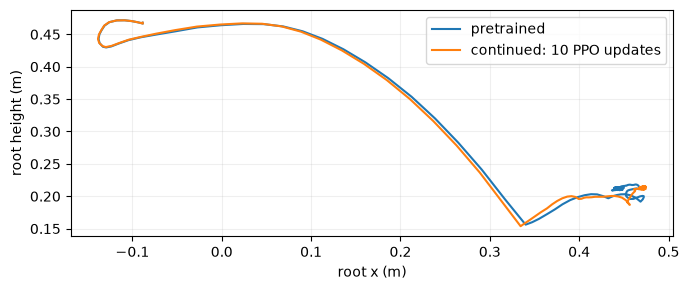

In [9]:
candidate = lesson.render_episode(SOURCE, PYTHON, TRAIN_OUTPUT / "continued.pt",
                                  OUTPUT / "long_jump_continued_latest.mp4", seed=SEED)
print({key: candidate[key] for key in ("backend", "video_seconds", "termination", "landed_on_target", "final_target_support", "final_position_m")})
selection = lesson.select_deployment_model(baseline, candidate, MODEL, TRAIN_OUTPUT)
print("候选模型任务评测：", "通过" if selection["candidate_accepted"] else "未通过，部署保留原始模型")
display(Video("outputs/long_jump/long_jump_continued_latest.mp4", embed=False, width=720,
              html_attributes='controls style="max-width:100%;height:auto;"'))
fig, ax = plt.subplots(figsize=(7, 3))
plot_episode(baseline, ax, "pretrained")
plot_episode(candidate, ax, "continued: 10 PPO updates")
plt.tight_layout()
plt.show()

## 10. 验证 ONNX 与 PyTorch 输出

使用随机观测和真实仿真观测对照两个运行时，确认归一化、动作边界与导出结果一致。
数值对齐与物理任务完成是两类检查，需要分别验收。

In [10]:
parity = lesson.verify_onnx(SOURCE, PYTHON, TRAIN_OUTPUT / "continued.pt",
                            TRAIN_OUTPUT / "policy.onnx", OUTPUT / "onnx_parity_latest.json")
print({key: parity[key] for key in ("observation_size", "action_size", "observations", "live_steps",
       "max_abs_action_error", "normalizer_baked_into_onnx", "action_filter")})
assert parity["max_abs_action_error"] < 1e-4

{'observation_size': 61, 'action_size': 14, 'observations': 200, 'live_steps': 100, 'max_abs_action_error': 3.874301910400391e-06, 'normalizer_baked_into_onnx': True, 'action_filter': 'none'}


## 11. 导出模型的闭环仿真

ONNX Runtime 接收实时 61 维观测，输出 14 维动作驱动同一物理场景。
本单元使用 CPU 运行 ONNX；上面的主线视频使用 GPU/PyTorch。
续训候选模型须完成跳跃、落地和 12 秒回合才用于部署，否则继续使用已通过评测的原始模型。

In [11]:
deployment_parity = lesson.verify_onnx(SOURCE, PYTHON, Path(selection["checkpoint"]),
                                      Path(selection["onnx"]), OUTPUT / "deployment_parity.json")
assert deployment_parity["max_abs_action_error"] < 1e-4
print("实际部署模型：", selection["selected"], selection["reason"])
deployed = lesson.render_episode(SOURCE, PYTHON, Path(selection["checkpoint"]),
                                 OUTPUT / "long_jump_onnx_latest.mp4", seed=SEED,
                                 backend="onnx", onnx=Path(selection["onnx"]))
assert deployed["landed_on_target"] and deployed["final_target_support"]
assert deployed["video_seconds"] >= 11.98 and "fell" not in deployed["termination"]
print({key: deployed[key] for key in ("backend", "video_seconds", "termination", "landed_on_target", "final_target_support", "final_position_m")})
display(Video("outputs/long_jump/long_jump_onnx_latest.mp4", embed=False, width=720,
              html_attributes='controls style="max-width:100%;height:auto;"'))

实际部署模型： continued candidate_task_passed


{'backend': 'ONNX Runtime CPU', 'video_seconds': 12.0, 'termination': ['time_out'], 'landed_on_target': True, 'final_target_support': True, 'final_position_m': [0.44870805740356445, 0.0601746030151844, 0.21388337016105652]}


## 12. 从零训练与后续实验

想研究奖励和课程，可以不加载检查点，从随机初始化开始训练。
下方生成上游训练入口，默认只展示命令；完整学习跨缝动作需要更多训练轮次。
先阅读 `microduck_platform_jump_env_cfg.py` 和 `experiments/parkour/TRAINING.md`，
区分训练时的间隙/高差课程与固定评测场景。

In [12]:
scratch_command = lesson.from_scratch_command(SOURCE, PYTHON, OUTPUT)
print("从源码目录执行：")
print(shlex.join(scratch_command))
print("本单元仅展示从零训练入口；上面的 10 轮续训已实际执行。")
print("建议比较：原始模型、续训模型、不同随机种子与不同间隙的完整回合。")

从源码目录执行：
/home/nvidia/microduck-course-run/jump-home/source-release/.venv/bin/python -m mjlab_microduck.train_cli Mjlab-PlatformJump-MicroDuck --env.scene.num-envs 4096 --agent.max-iterations 6000 --agent.logger tensorboard --agent.run-name long-jump-from-scratch
本单元仅展示从零训练入口；上面的 10 轮续训已实际执行。
建议比较：原始模型、续训模型、不同随机种子与不同间隙的完整回合。


## 13. 保存网页预览与实验记录

MP4、模型和日志留在 `outputs/long_jump/`，不嵌入 Notebook。
生成小体积 GIF 供 GitHub 阅读，报告记录模型哈希、源码版本和真实终止原因。

In [13]:
ASSETS = TOPIC / "01-任务资料/08-MicroDuck跨缝跳跃/assets"
ASSETS.mkdir(parents=True, exist_ok=True)
for name in ("pretrained", "continued", "onnx"):
    lesson.make_gif(OUTPUT / f"long_jump_{name}_latest.mp4", ASSETS / f"long_jump_{name}.gif")
summary = {"source_revision": lesson.SOURCE_REVISION, "model_revision": lesson.MODEL_REVISION,
           "seed": SEED, "training": training, "deployment_selection": selection,
           "episodes": {name: {k: report[k] for k in ("backend", "video_seconds", "termination",
                         "checkpoint_sha256", "final_position_m", "landed_on_target", "final_target_support", "final_upright_cos")}
                        for name, report in (("pretrained", baseline), ("continued", candidate), ("onnx", deployed))}}
(OUTPUT / "lesson_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
display(Markdown("![跨缝跳跃](../01-任务资料/08-MicroDuck跨缝跳跃/assets/long_jump_pretrained.gif)"))
print("已保存原始模型、续训模型、ONNX 的独立视频和实验报告。")

![跨缝跳跃](../01-任务资料/08-MicroDuck跨缝跳跃/assets/long_jump_pretrained.gif)

已保存原始模型、续训模型、ONNX 的独立视频和实验报告。
